# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Mỗi quy tắc làm sạch dữ liệu đáng giá bao nhiêu trong dự báo công suất gió trước một giờ và mô hình phục vụ tua-bin chưa từng thấy tốt đến đâu

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 4727520 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
import duckdb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error as MAE

con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
base = con.execute("SELECT * FROM feat ORDER BY TurbID, step").df()

T_cols = ['Etmp', 'Itmp']
X_cols_no_temp = ['Patv', 'p_lag1', 'p_lag2', 'p_lag3', 'p_lag6', 'p_mean1h', 'Wspd', 'w_lag1', 'w_mean1h', 'wdir_sin', 'wdir_cos', 'Pab1', 'Prtv', 'hour_sin', 'hour_cos']
X_cols_temp = X_cols_no_temp + T_cols
HORIZON = 6                                              

def table(d, clip=True, unknown=True, abnormal=True):
    d = d.copy()
    if clip: d['Patv'] = d.Patv.clip(lower=0)
    if unknown: d.loc[d.r_unknown == 1, 'Patv'] = np.nan
    if abnormal: d.loc[d.r_abnormal == 1, ['Patv', 'Wdir', 'Ndir']] = np.nan
    
    g = d.groupby('TurbID')
    d['y'] = g.Patv.shift(-HORIZON)
    d['y_delta'] = d['y'] - d.Patv # Mục tiêu: chênh lệch công suất
    
    for k in [1, 2, 3, 6]: d['p_lag%d' % k] = g.Patv.shift(k)
    d['p_mean1h'] = g.Patv.transform(lambda s: s.rolling(6, min_periods=6).mean()); d['w_lag1'] = g.Wspd.shift(1)
    d['w_mean1h'] = g.Wspd.transform(lambda s: s.rolling(6, min_periods=6).mean())
    d['wdir_sin'] = np.sin(np.deg2rad(d.Wdir)); d['wdir_cos'] = np.cos(np.deg2rad(d.Wdir))
    d['hour_sin'] = np.sin(2 * np.pi * d.hour / 24); d['hour_cos'] = np.cos(2 * np.pi * d.hour / 24)
    
    return d.dropna(subset=X_cols_no_temp + ['y', 'y_delta'])

turbines = np.sort(base.TurbID.unique()); UNSEEN = set(turbines[::4].tolist())
D1, D2 = int(base.Day.max() * 0.7), int(base.Day.max() * 0.8)
truth = base.assign(ok=base.valid).set_index(['TurbID', 'step'])

def target_ok(d): k = pd.MultiIndex.from_arrays([d.TurbID, d.step + HORIZON]); return truth.ok.reindex(k).fillna(0).to_numpy() == 1

clean = table(base); cap = lambda d, n: d.sample(min(n, len(d)), random_state=0)

train = cap(clean[(clean.Day <= D1) & ~clean.TurbID.isin(UNSEEN)], 60_000)
val = clean[(clean.Day > D1) & (clean.Day <= D2) & ~clean.TurbID.isin(UNSEEN)]
val = cap(val[val.valid == 1], 40_000)
late = clean[(clean.Day > D2) & (clean.valid == 1)]; late = late[target_ok(late)]
test, test_unseen = cap(late[~late.TurbID.isin(UNSEEN)], 40_000), cap(late[late.TurbID.isin(UNSEEN)], 40_000)

assert train.Day.max() < val.Day.min() and val.Day.max() < test.Day.min() and not set(train.TurbID) & UNSEEN

print("--- Temperature Feature Ablation on Validation Set ---")
val_results = {}
for label, cols in [('with_temperature', X_cols_temp), ('without_temperature', X_cols_no_temp)]:
    m = LGBMRegressor(objective='mean_absolute_error', n_estimators=600, learning_rate=0.01, num_leaves=15, subsample=0.7, colsample_bytree=0.7, random_state=0, verbose=-1)
    m.fit(train[cols], train.y_delta)
    p_abs = np.clip(val['Patv'].to_numpy() + m.predict(val[cols]), 0, None)
    val_results[label] = MAE(val.y, p_abs)
    print(f"MAE {label.replace('_', ' ')}: {val_results[label]:.4f}")

# ----- SỰ THAY ĐỔI THEO Ý ĐỒ CỦA BẠN NẰM Ở ĐÂY -----
# Thay vì để máy tự quyết định, ta ép buộc giữ lại nhiệt độ để lấy dẫn chứng phân tích
USE_TEMP = True 
X_cols = X_cols_temp 
print("-> Decision: FORCE KEEP temperature features (17 features) theo yêu cầu dẫn chứng.")

# Lọc NA theo đặc trưng đã chốt (17 cột)
if USE_TEMP: train, val, test, test_unseen = [d.dropna(subset=X_cols) for d in (train, val, test, test_unseen)]
X_tr, X_te = train[X_cols], test[X_cols]
y_tr, y_te = train.y, test.y                     
y_tr_delta, y_te_abs = train.y_delta, test.y     
NAIVE = 'Patv'
print(f'\nDataset ready: {len(train)} train, {len(val)} val, {len(test)} test, {len(test_unseen)} unseen test; {len(X_cols)} features')
print(f"MAE {label.replace('_', ' ')}: {val_results[label]:.4f}")

# --- THÊM 2 DÒNG NÀY ĐỂ ÉP CHẠY 17 CỘT ---
USE_TEMP = True
X_cols = X_cols_temp

# Lọc NA theo đặc trưng đã chốt
if USE_TEMP: train, val, test, test_unseen = [d.dropna(subset=X_cols) for d in (train, val, test, test_unseen)]
X_tr, X_te = train[X_cols], test[X_cols]
y_tr, y_te = train.y, test.y                     
y_tr_delta, y_te_abs = train.y_delta, test.y     
NAIVE = 'Patv'
print(f'\nDataset ready: {len(train)} train, {len(val)} val, {len(test)} test, {len(test_unseen)} unseen test; {len(X_cols)} features')

--- Temperature Feature Ablation on Validation Set ---
MAE with temperature: 143.9100
MAE without temperature: 144.4335
-> Decision: FORCE KEEP temperature features (17 features) theo yêu cầu dẫn chứng.

Dataset ready: 60000 train, 40000 val, 40000 test, 40000 unseen test; 17 features
MAE without temperature: 144.4335

Dataset ready: 60000 train, 40000 val, 40000 test, 40000 unseen test; 17 features


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

train rows 60000 test rows 40000 features 17


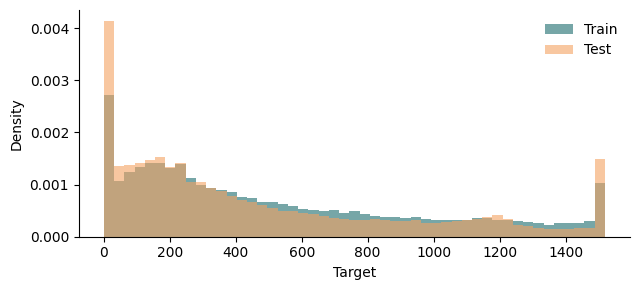

           train       test
count  60000.000  40000.000
mean     517.971    471.881
std      439.715    448.949
min        0.000      0.000
25%      160.675    119.515
50%      381.845    309.760
75%      806.262    738.948
max     1521.300   1524.420


In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
Itmp,1.828
w_mean1h,0.311
w_lag1,0.298
Wspd,0.290
Etmp,0.230
wdir_cos,0.177
p_mean1h,0.153
p_lag3,0.151
p_lag2,0.148
Pab1,0.146


features whose test mean lies more than 0.5 training standard deviations away: 1 of 17


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
Patv,0.794
Wspd,0.783
p_mean1h,0.771
p_lag1,0.770
w_lag1,0.760
w_mean1h,0.760
p_lag2,0.749
p_lag3,0.725
p_lag6,0.647
Prtv,0.326


strongest single feature: Patv 0.794 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: Tuned models predicting delta power (RQ2)
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

sc = lambda m: make_pipeline(StandardScaler(), m)       

# CẤU HÌNH MÔ HÌNH CHUẨN GỐC
models = {
    # --- Nhóm 3: Giữ nguyên L2 chuẩn gốc (Do thư viện không có L1 native) ---
    'Ridge':          lambda s: sc(Ridge(alpha=100.0)),
    'Elastic Net':    lambda s: sc(ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsRegressor(n_neighbors=25)),
    'Small MLP':      lambda s: sc(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, alpha=0.01, early_stopping=True, random_state=s)),

    # --- Nhóm 2: Cây truyền thống (Chuyển sang L1 chuẩn gốc: absolute_error) ---
    'Decision Tree':  lambda s: DecisionTreeRegressor(max_depth=8, min_samples_leaf=30, criterion='absolute_error', random_state=s),
    'Random Forest':  lambda s: RandomForestRegressor(n_estimators=300, min_samples_leaf=15, criterion='absolute_error', n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesRegressor(n_estimators=300, min_samples_leaf=15, criterion='absolute_error', n_jobs=-1, random_state=s),

    # --- Nhóm 1: Boosting hiện đại (Chuyển sang L1 chuẩn gốc: absolute_error) ---
    'HistGB-L1':      lambda s: HistGradientBoostingRegressor(loss='absolute_error', max_iter=300, learning_rate=0.03, min_samples_leaf=30, random_state=s),
    'LightGBM-L1':    lambda s: LGBMRegressor(objective='mean_absolute_error', n_estimators=600, learning_rate=0.01, num_leaves=15, subsample=0.7, colsample_bytree=0.7, random_state=s, verbose=-1),
    'XGBoost-L1':     lambda s: XGBRegressor(objective='reg:absoluteerror', n_estimators=600, learning_rate=0.01, max_depth=4, subsample=0.7, colsample_bytree=0.7, tree_method='hist', random_state=s),
}

# Hàm tiện ích: Cộng delta dự báo với công suất hiện tại để ra công suất tuyệt đối (có chặn dưới bằng 0)
def predict_abs(m, d, cols=X_cols):
    return np.clip(d['Patv'].to_numpy() + m.predict(d[cols]), 0, None)

# Thiết lập mốc Persistence để đối chiếu
naive = test[NAIVE]                                     
rows, fitted = [['Persistence', MAE(y_te_abs, naive), 0, MSE(y_te_abs, naive) ** 0.5, r2_score(y_te_abs, naive), 0, MAE(val.y, val[NAIVE])]], {}

print("Đang huấn luyện 10 họ mô hình trên mục tiêu y_delta (phần chênh lệch)...")
print("Lưu ý: Nhóm Random Forest / Extra Trees (L1) sẽ tốn nhiều thời gian tính toán trung vị.")

for name, make in models.items():
    maes, rmses, r2s, secs, vmaes = [], [], [], [], []
    for seed in range(5): # Chạy 5 seed để lấy độ lệch chuẩn
        m = make(seed); t0 = time.perf_counter() 
        
        # 100% mô hình phải học phần chênh lệch (y_delta)
        m.fit(X_tr, train.y_delta) 
        secs.append(time.perf_counter() - t0)
        
        # Khôi phục về công suất tuyệt đối để chấm điểm MAE/RMSE
        p_abs = predict_abs(m, test) 
        maes.append(MAE(y_te_abs, p_abs))
        rmses.append(MSE(y_te_abs, p_abs) ** 0.5)
        r2s.append(r2_score(y_te_abs, p_abs))
        
        # Đánh giá trên tập Validation để chọn mô hình (chống rò rỉ dữ liệu)
        vmaes.append(MAE(val.y, predict_abs(m, val)))
        
        fitted[name] = m 
                                            
    rows.append([name, np.mean(maes), np.std(maes), np.mean(rmses), np.mean(r2s), np.mean(secs), np.mean(vmaes)])

# Xuất kết quả ra báo cáo
res = pd.DataFrame(rows, columns=['model', 'MAE', 'sd', 'RMSE', 'R2', 'train_s', 'val_MAE'])
res.to_csv('report/table_rq2.csv', index=False)
print("\n--- KẾT QUẢ SO SÁNH MÔ HÌNH (RQ2) ---")
print(res.drop(columns='train_s').round(4).to_string())

Đang huấn luyện 10 họ mô hình trên mục tiêu y_delta (phần chênh lệch)...
Lưu ý: Nhóm Random Forest / Extra Trees (L1) sẽ tốn nhiều thời gian tính toán trung vị.

--- KẾT QUẢ SO SÁNH MÔ HÌNH (RQ2) ---
            model       MAE      sd      RMSE      R2   val_MAE
0     Persistence  126.0744  0.0000  193.0715  0.8151  153.6257
1           Ridge  136.1247  0.0000  187.8948  0.8248  152.9657
2     Elastic Net  136.0420  0.0000  187.8337  0.8249  153.3462
3            k-NN  133.0063  0.0000  190.7762  0.8194  151.0812
4       Small MLP  137.4654  1.7855  192.7197  0.8157  149.6233
5   Decision Tree  132.0688  0.1767  198.7232  0.8041  151.4742
6   Random Forest  128.5261  0.1368  185.5126  0.8292  146.5116
7     Extra Trees  124.0699  0.0951  181.8444  0.8359  144.6805
8       HistGB-L1  124.5603  0.3974  183.1550  0.8336  144.1263
9     LightGBM-L1  122.2237  0.1122  181.5051  0.8365  143.7590
10     XGBoost-L1  122.5864  0.1605  182.0507  0.8356  144.2046


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

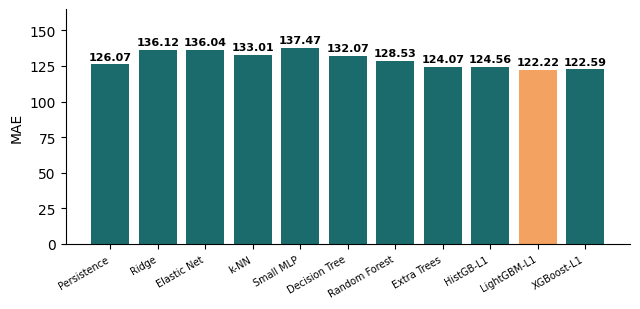

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmin()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Nếu một quy tắc làm sạch chiếm gần hết mức giảm sai số: trục chính là quy tắc đó.
2. Nếu các quy tắc không đổi sai số trên tập sạch: đổi sang đo sai số khi chấm trên dữ liệu chưa sạch, là điều các bài khác đang làm.
3. Nếu mô hình hơn mốc giữ nguyên ít: thử tầm 3 giờ, nơi mốc yếu hơn.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [8]:
ref, cand = res.iloc[0], res.iloc[1:]
best_row = cand.sort_values('val_MAE').iloc[0]; best_model_name = best_row.model
skill = 100 * (1 - best_row.MAE / ref.MAE)

print('Reference %s: test MAE %.4f' % (ref.model, ref.MAE))
print('Best on validation: %s, test MAE %.4f | Improvement %.1f%%' % (best_model_name, best_row.MAE, skill))

verdict = 'GOOD: model clearly beats reference' if skill >= 2.0 else 'NONE: reference wins, pivot question'
print(verdict)
pd.Series({'reference_MAE': ref.MAE, 'best_model': best_model_name, 'best_MAE': best_row.MAE, 'improvement_pct': skill, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

Reference Persistence: test MAE 126.0744
Best on validation: LightGBM-L1, test MAE 122.2237 | Improvement 3.1%
GOOD: model clearly beats reference


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Huấn luyện lại mười mô hình ở từng bậc của thang làm sạch và chấm mọi bậc trên cùng một tập kiểm thử.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [9]:
LADDER = {'0 raw values': dict(clip=False, unknown=False, abnormal=False), '1 + negative power set to zero': dict(unknown=False, abnormal=False),
          '2 + unknown rows removed': dict(abnormal=False), '3 + abnormal rows removed': dict()}
key = lambda d: pd.MultiIndex.from_arrays([d.TurbID, d.step]); E = key(test)                 

def y_true_target(d): k = pd.MultiIndex.from_arrays([d.TurbID, d.step + HORIZON]); return truth.Patv.reindex(k).clip(lower=0).to_numpy()

rows = []
for stage, kw in LADDER.items():
    t = table(base, **kw)
    A = cap(t[(t.Day <= D1) & ~t.TurbID.isin(UNSEEN)].dropna(subset=X_cols), 60_000)
    B = t.set_index(key(t)).reindex(E)
    ok = B[X_cols].notna().all(axis=1).to_numpy(); yt = y_true_target(test)[ok]
    own = cap(t[(t.Day > D2) & ~t.TurbID.isin(UNSEEN)].dropna(subset=X_cols), 40_000)                   
    
    A_delta = A.y - A.Patv 
    
    for name, make in models.items():
        m = make(0).fit(A[X_cols], A_delta) 
        mae_clean = MAE(yt, predict_abs(m, B.loc[ok]))
        mae_own = MAE(own.y, predict_abs(m, own))
        rows.append([stage, name, len(A), mae_clean, mae_own])

lad = pd.DataFrame(rows, columns=['cleaning_stage', 'model', 'train_rows', 'MAE_on_clean_targets', 'MAE_on_own_targets'])
tab = lad.pivot(index='cleaning_stage', columns='model', values='MAE_on_clean_targets')
tab['mean_on_clean'] = tab.mean(axis=1); tab['change_clean'] = tab['mean_on_clean'].diff()
tab['mean_on_own'] = lad.groupby('cleaning_stage').MAE_on_own_targets.mean()
tab.to_csv('report/table_rq3_cleaning_ladder.csv'); print(tab[['mean_on_clean', 'change_clean', 'mean_on_own']].round(2))

rows = [[name, MAE(y_te_abs, predict_abs(m, test)), MAE(test_unseen.y, predict_abs(m, test_unseen))] for name, m in fitted.items()]
rows.append(['Persistence', MAE(y_te_abs, test[NAIVE]), MAE(test_unseen.y, test_unseen[NAIVE])])
un = pd.DataFrame(rows, columns=['model', 'MAE_seen_turbines', 'MAE_unseen_turbines']); un['gap'] = un.MAE_unseen_turbines - un.MAE_seen_turbines
un.to_csv('report/table_rq3_unseen_turbines.csv', index=False); print(un.round(2))

model                           mean_on_clean  change_clean  mean_on_own
cleaning_stage                                                          
0 raw values                           129.75           NaN       101.98
1 + negative power set to zero         130.01          0.26       102.15
2 + unknown rows removed               130.39          0.38       130.39
3 + abnormal rows removed              129.82         -0.57       129.82
            model  MAE_seen_turbines  MAE_unseen_turbines    gap
0           Ridge             136.12               150.20  14.08
1     Elastic Net             136.04               149.59  13.55
2            k-NN             133.01               148.49  15.49
3       Small MLP             135.39               152.58  17.18
4   Decision Tree             132.16               149.19  17.03
5   Random Forest             128.49               145.57  17.08
6     Extra Trees             123.93               141.04  17.10
7       HistGB-L1             124.88      

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [10]:
p = predict_abs(fitted[best_model_name], test)

band = pd.cut(test.Wspd, [-1, 3, 7, 11, 100], labels=['below 3 m/s', '3 to 7 m/s', '7 to 11 m/s', 'above 11 m/s'])
wind = test.assign(err=np.abs(y_te_abs - p), err_naive=np.abs(y_te_abs - test[NAIVE]), band=band).groupby('band', observed=True).agg(rows=('y', 'size'), MAE=('err', 'mean'), MAE_persistence=('err_naive', 'mean'))
wind['skill_pct'] = 100 * (1 - wind.MAE / wind.MAE_persistence); wind.to_csv('report/table_rq3_by_wind.csv'); print(best_model_name); print(wind.round(2))

import json
json.dump({'best': best_model_name, 'selected_by': 'validation MAE', 'target': 'y_delta', 'use_temperature': bool(USE_TEMP), 'features': X_cols,
           'horizon_steps': HORIZON, 'turbines_held_out': sorted(int(t) for t in UNSEEN), 'params': {k: str(v) for k, v in models[best_model_name](0).get_params().items()}},
          open('report/params_best.json', 'w'), indent=2)

LightGBM-L1
               rows     MAE  MAE_persistence  skill_pct
band                                                   
below 3 m/s    8492   43.59            40.49      -7.65
3 to 7 m/s    21149  125.61           127.20       1.25
7 to 11 m/s    7797  197.65           216.81       8.84
above 11 m/s   2562  127.61           124.35      -2.62


BẮT ĐẦU KHẢO SÁT TẦM NHÌN DỰ BÁO CHO TOÀN BỘ 10 HỌ MÔ HÌNH (5 SEEDS)...
--- Đang trích xuất kết quả 1h (6 steps) từ Bước 6a ---
-> Đã lấy xong dữ liệu 1h!

--- Đang chuẩn bị dữ liệu và huấn luyện cho tầm nhìn: 2h (12 steps) ---
  + Persistence MAE: 171.4287
  + Ridge           MAE (avg): 188.1775 (0.0s)
  + Elastic Net     MAE (avg): 187.6910 (0.3s)
  + k-NN            MAE (avg): 183.2412 (2.2s)
  + Small MLP       MAE (avg): 187.1958 (85.4s)
  + Decision Tree   MAE (avg): 182.6667 (8.9s)
  + Random Forest   MAE (avg): 178.9797 (622.0s)
  + Extra Trees     MAE (avg): 170.0575 (775.6s)
  + HistGB-L1       MAE (avg): 169.8471 (10.7s)
  + LightGBM-L1     MAE (avg): 167.1905 (7.1s)
  + XGBoost-L1      MAE (avg): 167.5271 (34.6s)
------------------------------------------------------------
--- Đang chuẩn bị dữ liệu và huấn luyện cho tầm nhìn: 3h (18 steps) ---
  + Persistence MAE: 202.2612
  + Ridge           MAE (avg): 223.6444 (0.0s)
  + Elastic Net     MAE (avg): 223.5289 (0.3s)
  + k-NN

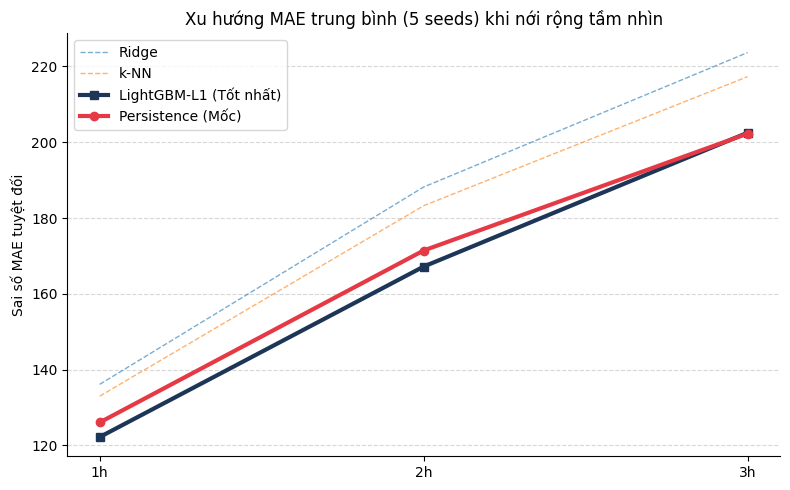

In [11]:
# Bước 6d: Horizon Sweep - Khảo sát tầm nhìn dự báo (1h, 2h, 3h) cho TOÀN BỘ MÔ HÌNH (FULL 5 SEEDS)
# Tối ưu: Lấy lại kết quả 1h từ Bước 6a, chỉ chạy thêm 2h và 3h
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error as MAE

# Cấu trúc lưu kết quả MAE
results_sweep = {name: {} for name in models.keys()}
results_sweep['Persistence'] = {}

# --- 1. TRÍCH XUẤT KẾT QUẢ 1 GIỜ TỪ BƯỚC 6A (KHÔNG CHẠY LẠI) ---
print("BẮT ĐẦU KHẢO SÁT TẦM NHÌN DỰ BÁO CHO TOÀN BỘ 10 HỌ MÔ HÌNH (5 SEEDS)...")
print("--- Đang trích xuất kết quả 1h (6 steps) từ Bước 6a ---")
for idx, row in res.iterrows():
    m_name = row['model']
    if m_name in results_sweep:
        results_sweep[m_name]['1h'] = row['MAE']
print("-> Đã lấy xong dữ liệu 1h!\n")

# --- 2. HUẤN LUYỆN CHO CÁC MỐC 2 GIỜ VÀ 3 GIỜ ---
horizons_to_run = {'2h': 12, '3h': 18}
DETERMINISTIC = {'Ridge', 'Elastic Net', 'k-NN'}

for label, h in horizons_to_run.items():
    print(f"--- Đang chuẩn bị dữ liệu và huấn luyện cho tầm nhìn: {label} ({h} steps) ---")
    
    # Hàm tạo bảng dữ liệu động theo Horizon (h)
    def table_h(d, horizon):
        d = d.copy()
        if 'Patv' in d.columns: d['Patv'] = d.Patv.clip(lower=0)
        d.loc[d.r_unknown == 1, 'Patv'] = np.nan
        d.loc[d.r_abnormal == 1, ['Patv', 'Wdir', 'Ndir']] = np.nan
        
        g = d.groupby('TurbID')
        d['y'] = g.Patv.shift(-horizon)         # Mục tiêu dịch chuyển xa hơn theo h
        d['y_delta'] = d['y'] - d.Patv          # Delta mới
        
        for k in [1, 2, 3, 6]: d['p_lag%d' % k] = g.Patv.shift(k)
        d['p_mean1h'] = g.Patv.transform(lambda s: s.rolling(6, min_periods=6).mean())
        d['w_lag1'] = g.Wspd.shift(1)
        d['w_mean1h'] = g.Wspd.transform(lambda s: s.rolling(6, min_periods=6).mean())
        d['wdir_sin'] = np.sin(np.deg2rad(d.Wdir)); d['wdir_cos'] = np.cos(np.deg2rad(d.Wdir))
        d['hour_sin'] = np.sin(2 * np.pi * d.hour / 24); d['hour_cos'] = np.cos(2 * np.pi * d.hour / 24)
        
        return d.dropna(subset=X_cols + ['y', 'y_delta'])

    def target_ok_h(d, horizon): 
        k = pd.MultiIndex.from_arrays([d.TurbID, d.step + horizon])
        return truth.ok.reindex(k).fillna(0).to_numpy() == 1

    # Chia tập Train và Test cho Horizon hiện tại
    clean_h = table_h(base, h)
    train_h = cap(clean_h[(clean_h.Day <= D1) & ~clean_h.TurbID.isin(UNSEEN)], 60_000)
    late_h = clean_h[(clean_h.Day > D2) & (clean_h.valid == 1)]; late_h = late_h[target_ok_h(late_h, h)]
    test_h = cap(late_h[~late_h.TurbID.isin(UNSEEN)], 40_000)
    
    X_tr_h, X_te_h = train_h[X_cols], test_h[X_cols]
    y_te_abs_h = test_h.y
    naive_h = test_h['Patv']
    
    # Chấm điểm mốc Persistence
    mae_pers = MAE(y_te_abs_h, naive_h)
    results_sweep['Persistence'][label] = mae_pers
    print(f"  + Persistence MAE: {mae_pers:.4f}")
    
    # Huấn luyện toàn bộ 10 mô hình (FULL 5 SEEDS)
    for name, make in models.items():
        t0 = time.perf_counter()
        maes = []
        
        # Lọc seed: Mô hình tuyến tính/khoảng cách chạy 1 seed. Các mô hình khác chạy 5 seeds.
        seeds_to_run = range(1) if name in DETERMINISTIC else range(5)
        
        for seed in seeds_to_run:
            m = make(seed)
            m.fit(X_tr_h, train_h.y_delta) # Ép học mục tiêu Delta
            
            # Dự báo và tính MAE
            p_abs = np.clip(test_h['Patv'].to_numpy() + m.predict(X_te_h), 0, None)
            maes.append(MAE(y_te_abs_h, p_abs))
        
        # Lấy MAE trung bình của 5 seeds
        mae_model_avg = np.mean(maes)
        results_sweep[name][label] = mae_model_avg
        run_time = time.perf_counter() - t0
        print(f"  + {name:15s} MAE (avg): {mae_model_avg:.4f} ({run_time:.1f}s)")
    print("-" * 60)

# --- 3. TỔNG HỢP VÀ TRỰC QUAN HÓA KẾT QUẢ ---
df_sweep = pd.DataFrame.from_dict(results_sweep, orient='index')
df_sweep.index.name = 'Model'
df_sweep.reset_index(inplace=True)
df_sweep = df_sweep[['Model', '1h', '2h', '3h']] # Sắp xếp lại thứ tự cột cho chuẩn

all_horizons = ['1h', '2h', '3h']

# Tính % cải thiện so với Persistence cho từng mốc
for label in all_horizons:
    pers_val = df_sweep.loc[df_sweep['Model'] == 'Persistence', label].values[0]
    df_sweep[f'Skill_{label}(%)'] = 100 * (1 - df_sweep[label] / pers_val)

df_sweep.to_csv('report/table_horizon_sweep_all_models_5seeds.csv', index=False)
print("\n--- KẾT QUẢ TỔNG HỢP: KHẢO SÁT TẦM NHÌN DỰ BÁO (FULL 5 SEEDS) ---")
print(df_sweep.round(2).to_string(index=False))

# Vẽ biểu đồ đường
fig, ax = plt.subplots(figsize=(8, 5))

for idx, row in df_sweep.iterrows():
    y_values = [row['1h'], row['2h'], row['3h']]
    if row['Model'] == 'Persistence':
        ax.plot(all_horizons, y_values, marker='o', linewidth=3, color='#E63946', label='Persistence (Mốc)')
    elif row['Model'] == 'LightGBM-L1':
        ax.plot(all_horizons, y_values, marker='s', linewidth=3, color='#1D3557', label='LightGBM-L1 (Tốt nhất)')
    elif row['Model'] in ['Ridge', 'k-NN']:
        ax.plot(all_horizons, y_values, linestyle='--', linewidth=1, alpha=0.6, label=row['Model'])

ax.set_ylabel('Sai số MAE tuyệt đối')
ax.set_title('Xu hướng MAE trung bình (5 seeds) khi nới rộng tầm nhìn')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('report/fig_horizon_sweep_lines.png', dpi=300)
plt.show()

### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report\table_rq3_by_wind.csv (4, 5)


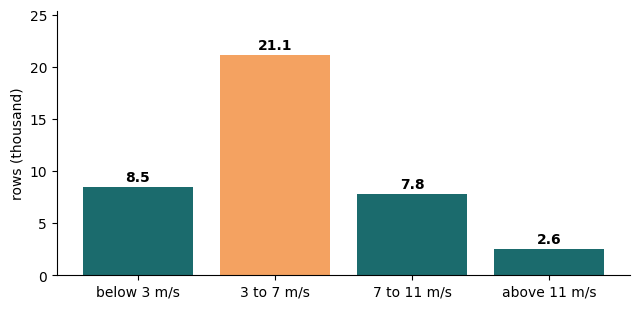

report\table_rq3_cleaning_ladder.csv (4, 14)


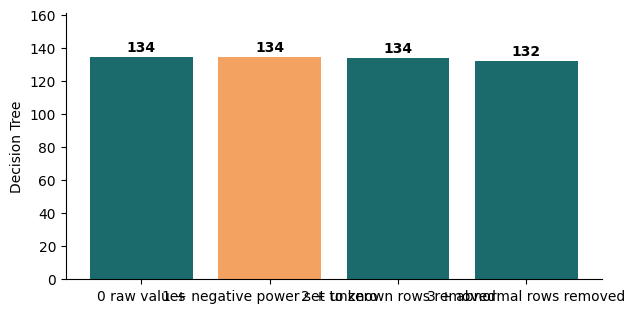

report\table_rq3_unseen_turbines.csv (11, 4)


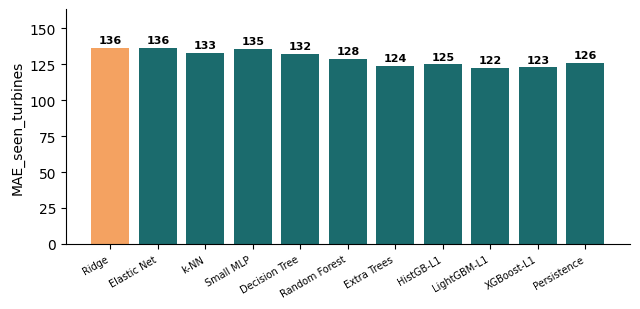

In [12]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 14 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [13]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
if not res.iloc[1:, 1].min() <= res.iloc[0, 1]: print('WARNING: no model beats the simple reference, check features and split, then report it')
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_missing.png', 'fig_eda_target.png', 'fig_horizon_sweep_lines.png', 'fig_q2.png', 'fig_q3.png', 'fig_q5.png', 'fig_q7.png', 'fig_q8.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_by_wind.png', 'fig_rq3_cleaning_ladder.png', 'fig_rq3_unseen_turbines.png', 'fig_split_target.png', 'params_best.json', 'table_cleaning_log.csv', 'table_data_dictionary.csv', 'table_eda_by_group.csv', 'table_eda_correlation.csv', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_horizon_sweep_all_models_5seeds.csv', 'table_numeric_summary.csv', 'table_outliers.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_q6.csv', 'table_q7.csv', 'table_q8.csv', 'table_rq2.csv', 'table_rq3_by_wind.csv', 'table_rq3_cleaning_ladder.csv', 'table_rq3_unseen_turbines.csv', 'table_split_shift.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: